In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
pd.set_option('display.max_columns', None)
import yfinance as yf


In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'SANB11.SA'
papeis_adicionais = ['BBAS3.SA', 'BBDC4.SA', 'ITUB4.SA']

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
df_base = pp.buscar_dados_papeis_adicionais(df_base, papeis_adicionais)
df_base.tail(10)

[SANB11.SA] Cache existente cobre de 2020-01-02 a 2025-06-24.
[SANB11.SA] Cache cobre período solicitado (2023-01-05 a 2025-06-23).
[SANB11.SA] Retornando 613 linhas para o período solicitado.
✅ Usando cache local: ../dados\macro_20220105_20250624.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-06-24.
[^BVSP] Cache cobre período solicitado (2023-01-05 a 2025-06-23).
[^BVSP] Retornando 613 linhas para o período solicitado.
<class 'datetime.date'> <class 'datetime.date'>
2023-01-05 2025-06-23
[BBAS3.SA] Cache existente cobre de 2020-01-02 a 2025-06-24.
[BBAS3.SA] Cache cobre período solicitado (2023-01-05 a 2025-06-23).
[BBAS3.SA] Retornando 613 linhas para o período solicitado.
<class 'datetime.date'> <class 'datetime.date'>
2023-01-05 2025-06-23
[BBDC4.SA] Cache existente cobre de 2020-01-02 a 2025-06-23.
[BBDC4.SA] Cache cobre período solicitado (2023-01-05 a 2025-06-23).
[BBDC4.SA] Retornando 613 linhas para o período solicitado.
<class 'datetime.date'> <class 'datetime.date'>

,open,high,low,close,volume,pct_change,vol,rsi,macd,macd_signal,macd_hist,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,volume_ibov,adc_open_BBAS3,adc_high_BBAS3,adc_low_BBAS3,adc_close_BBAS3,adc_volume_BBAS3,adc_pct_change_BBAS3,adc_vol_BBAS3,adc_rsi_BBAS3,adc_macd_BBAS3,adc_macd_signal_BBAS3,adc_macd_hist_BBAS3,adc_tr_BBAS3,adc_atr_BBAS3,adc_atr_pct_BBAS3,adc_tr_pct_BBAS3,adc_mm5_BBAS3,adc_mm20_BBAS3,adc_open_BBDC4,adc_high_BBDC4,adc_low_BBDC4,adc_close_BBDC4,adc_volume_BBDC4,adc_pct_change_BBDC4,adc_vol_BBDC4,adc_rsi_BBDC4,adc_macd_BBDC4,adc_macd_signal_BBDC4,adc_macd_hist_BBDC4,adc_tr_BBDC4,adc_atr_BBDC4,adc_atr_pct_BBDC4,adc_tr_pct_BBDC4,adc_mm5_BBDC4,adc_mm20_BBDC4,adc_open_ITUB4,adc_high_ITUB4,adc_low_ITUB4,adc_close_ITUB4,adc_volume_ITUB4,adc_pct_change_ITUB4,adc_vol_ITUB4,adc_rsi_ITUB4,adc_macd_ITUB4,adc_macd_signal_ITUB4,adc_macd_hist_ITUB4,adc_tr_ITUB4,adc_atr_ITUB4,adc_atr_pct_ITUB4,adc_tr_pct_ITUB4,adc_mm5_ITUB4,adc_mm20_ITUB4
data,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-06-09,28.750000,28.850000,28.360001,28.750000,2672900,0.000696,0.008394,42.697693,0.067197,0.322887,-0.255691,0.490000,0.658312,0.022898,0.017043,29.036,29.8225,14.75,0.26,5.5760,136102.0,136106.0,134119.0,135699.0,7763800,21.709999,22.000000,21.469999,21.730000,47713300,0.000921,0.009244,17.652746,-1.562503,-1.305298,-0.257205,0.530001,0.628626,0.028929,0.024390,22.202,24.7245,15.940000,16.030001,15.550000,15.840000,28177300,-0.007519,0.013779,60.855177,0.560497,0.660768,-0.100271,0.480000,0.402311,0.025398,0.030303,16.144,15.8025,36.135168,36.293699,35.540674,36.055901,23946500,-0.005194,0.005797,48.591048,0.405866,0.729336,-0.323470,0.753025,0.687638,0.019071,0.020885,36.349183,37.046783
2025-06-10,29.000000,29.030001,28.540001,28.830000,2133700,0.002783,0.008525,43.999704,0.021428,0.262595,-0.241168,0.490000,0.646290,0.022417,0.016996,28.856,29.7485,14.75,0.26,5.5557,135716.0,137369.0,135716.0,136436.0,8186500,21.879999,21.910000,21.299999,21.540001,43092300,-0.008744,0.008875,16.998014,-1.585610,-1.361361,-0.224250,0.610001,0.627295,0.029122,0.028319,21.914,24.3185,15.990000,16.040001,15.770000,15.830000,27623200,-0.000631,0.011954,60.592712,0.510160,0.630647,-0.120487,0.270000,0.392860,0.024817,0.017056,16.010,15.8330,36.500000,36.580002,35.970001,36.000000,20363600,-0.001550,0.004243,47.897989,0.326377,0.648744,-0.322367,0.610001,0.682092,0.018947,0.016944,36.211179,37.018098
2025-06-11,29.200001,30.350000,29.090000,30.170000,6945600,0.046479,0.017953,60.279714,0.092219,0.228520,-0.136301,1.520000,0.708698,0.023490,0.050381,29.084,29.7365,14.75,0.26,5.5390,136443.0,137531.0,135628.0,137128.0,8767100,21.500000,21.830000,21.400000,21.400000,32228100,-0.006500,0.008730,16.512034,-1.596813,-1.408451,-0.188362,0.430000,0.613203,0.028654,0.020093,21.724,23.9005,15.770000,16.360001,15.650000,16.320000,48251000,0.030954,0.015633,67.898520,0.503996,0.605316,-0.101320,0.710001,0.415513,0.025460,0.043505,15.984,15.8890,35.970001,36.590000,35.740002,36.330002,16180000,0.009167,0.005887,52.229671,0.286704,0.576336,-0.289632,0.849998,0.694086,0.019105,0.023397,36.157009,36.993535
2025-06-12,30.000000,30.070000,29.610001,29.910000,1390700,-0.008618,0.018180,56.827659,0.125891,0.207994,-0.082104,0.559999,0.698076,0.023339,0.018723,29.278,29.7105,14.75,0.26,5.5388,137127.0,137931.0,136175.0,137800.0,7124600,21.389999,21.500000,21.040001,21.420000,28710900,0.000935,0.009433,16.877655,-1.585798,-1.443920,-0.141877,0.459999,0.602260,0.028117,0.021475,21.560,23.5015,16.209999,16.540001,16.139999,16.480000,38328100,0.009804,0.015720,69.863223,0.506187,0.585491,-0.079304,0.400002,0.414405,0.025146,0.024272,16.086,15.9455,36.090000,36.830002,36.060001,36.610001,21869400,0.007707,0.006465,55.602433,0.274691,0.516007,-0.241316,0.770000,0.699508,0.019107,0.021033,36.248013,36.958212
2025-06-13,29.740000,30.200001,29.440001,29.799999,3141200,-0.003678,0.018202,55.382599,0.142062,0.19480

## Verificação da volatilidade recente

In [7]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-06-09,0.658312,0.022898,0.490000,0.017043
2025-06-10,0.646290,0.022417,0.490000,0.016996
2025-06-11,0.708698,0.023490,1.520000,0.050381
2025-06-12,0.698076,0.023339,0.559999,0.018723
2025-06-13,0.702500,0.023574,0.760000,0.025503
2025-06-16,0.691607,0.022985,0.550001,0.018279
2025-06-17,0.674349,0.022366,0.449999,0.014925
2025-06-18,0.661896,0.022005,0.500000,0.016622
2025-06-20,0.663903,0.022528,0.690001,0.023414


In [8]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 2.27%
Valorização sugerida: 3.41%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [13]:
valorizacao = 0.04
stop_loss = 0.03
DIAS_FUTURO = 5  # dias futuros para buscar a valorização

In [14]:
df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df['Target'].value_counts(normalize=True)

Target
0.0    0.851974
1.0    0.148026
Name: proportion, dtype: float64

In [15]:
# estudo de qual tamanho de janela é melhor para este papel
tamanhos_janela = [6, 10, 15, 20, 30, 60]
f1_treino = []
f1_validacao = []

for tamanho_janela in tamanhos_janela:
    X, y = pp.preparar_X_y_agregado(df, tamanho_janela, dropna=True, tipo_drop_na='linhas')   

    X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)
    X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
    X_validacao = X_validacao[X_train.columns]

    modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
    modelo.fit(X_train.values, y_train.values)

    roc_treino, roc_validacao, diferenca, pr_auc_treino, pr_auc_validacao, f1_score_treino, f1_score_validacao = tr.comparar_auc_conjuntos(modelo, X_train, y_train, X_validacao, y_validacao)

    f1_treino.append(f1_score_treino)
    f1_validacao.append(f1_score_validacao)

df_resultados = pd.DataFrame({
    'Tamanho Janela': tamanhos_janela,
    'F1 Treino': f1_treino,
    'F1 Validação': f1_validacao
})

INFO: Papéis adicionais detectados para features: ['BBAS3', 'BBDC4', 'ITUB4']
INFO: 29 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.546
AUC na validação: 0.664
Diferença AUC (Treino - Validação): -0.117
PR AUC no treino: 0.317
PR AUC na validação: 0.391
Diferença PR AUC (Treino - Validação): -0.074
F1 Score no treino: 0.264
F1 Score na validação: 0.394
INFO: Papéis adicionais detectados para features: ['BBAS3', 'BBDC4', 'ITUB4']
INFO: 25 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.582
AUC na validação: 0.447
Diferença AUC (Treino - Validação): 0.135
PROVÁVEL OVERFITTING
PR AUC no treino: 0.352
PR AUC na validação: 0.249
Diferença PR AUC (Treino - Validação): 0.104
F1 Score no treino: 0.307
F1 Score na validação: 0.383
INFO: Papéis adicionais detectados para features: ['BBAS3', 'BBDC4', 'ITUB4']
INFO: 20 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


... (3 outputs left out)

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.624
AUC na validação: 0.494
Diferença AUC (Treino - Validação): 0.130
PROVÁVEL OVERFITTING
PR AUC no treino: 0.467
PR AUC na validação: 0.264
Diferença PR AUC (Treino - Validação): 0.203
F1 Score no treino: 0.373
F1 Score na validação: 0.377
INFO: Papéis adicionais detectados para features: ['BBAS3', 'BBDC4', 'ITUB4']


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.595
AUC na validação: 0.734
Diferença AUC (Treino - Validação): -0.139
PR AUC no treino: 0.407
PR AUC na validação: 0.465
Diferença PR AUC (Treino - Validação): -0.058
F1 Score no treino: 0.356
F1 Score na validação: 0.031


In [16]:
df_resultados.sort_values(by='F1 Validação', ascending=False)

,Tamanho Janela,F1 Treino,F1 Validação
3,20,0.355857,0.409355
0,6,0.264190,0.394181
1,10,0.307315,0.383327
2,15,0.386841,0.380616
4,30,0.373248,0.376958
5,60,0.355618,0.031160


In [17]:
# Preparar X e y para treino
DIAS_JANELA_X = 20  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True, tipo_drop_na='linhas')   

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

INFO: Papéis adicionais detectados para features: ['BBAS3', 'BBDC4', 'ITUB4']
INFO: 15 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


In [18]:
X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
X_validacao = X_validacao[X_train.columns]
print("Features removidas por alta correlação:", removidas)
print(f"Colunas restantes após filtragem: {X_train.shape[1]}")

Features removidas por alta correlação: ['retorno_acumulado', 'macd_ultimo_norm_atr_principal', 'tr_mean', 'macd_signal_ultimo', 'tr_std', 'ibov_amplitude', 'close_vs_mm20', 'macd_hist_ultimo', 'macd_mean', 'tr_ultimo', 'macd_signal_std', 'dias_queda_pct', 'close_amplitude', 'macd_ultimo', 'close_mean', 'macd_std_norm_atr_principal', 'rsi_mean']
Colunas restantes após filtragem: 70


In [19]:
X_train.tail()

,close_std,close_max,close_min,close_trend,retorno_desde_mudanca_close,close_dist_min,close_ult_vs_mm_janela,mm5_vs_mm20,retorno_mean,retorno_std,dias_alta_pct,retorno_medio_pos,retorno_medio_neg,volume_mean,volume_std,volume_trend,volume_ult_vs_mean,atr_ultimo,atr_pct_ultimo,rsi_std,rsi_ultimo,macd_std,macd_signal_mean,macd_signal_std_norm_atr_principal,macd_signal_ultimo_norm_atr_principal,macd_hist_mean,macd_hist_std,macd_hist_std_norm_atr_principal,macd_hist_ultimo_norm_atr_principal,tr_std_norm_atr_principal,tr_ultimo_norm_atr_principal,tr_pct_mean,tr_pct_std,tr_pct_ultimo,close_std_norm_atr_principal,close_amplitude_norm_atr_principal,adc_close_trend_BBAS3,adc_ret_acum_BBAS3,adc_rsi_ultimo_BBAS3,adc_atr_pct_ultimo_BBAS3,adc_macd_hist_ultimo_BBAS3,adc_correl_com_principal_BBAS3,adc_close_trend_BBDC4,adc_ret_acum_BBDC4,adc_rsi_ultimo_BBDC4,adc_atr_pct_ultimo_BBDC4,adc_macd_hist_ultimo_BBDC4,adc_correl_com_principal_BBDC4,adc_close_trend_ITUB4,adc_ret_acum_ITUB4,adc_rsi_ultimo_ITUB4,adc_atr_pct_ultimo_ITUB4,adc_macd_hist_ultimo_ITUB4,adc_correl_com_principal_ITUB4,adc_close_mean_geral_ultimo,close_vs_adc_close_mean_geral,adc_atr_pct_mean_geral_ultimo,adc_ret_acum_mean_geral_janela,selic_ultimo,ipca_ultimo,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,ibov_std,retorno_desde_mudanca_ibov,correl_papel_ibov,beta_papel_ibov,alpha_papel_vs_ibov_mean
2025-01-27,0.593921,25.360001,23.420000,0.085707,0.010467,1.680000,0.719500,0.024753,0.002826,0.014539,0.60,0.011659,-0.011912,2770550.0,1.905339e+06,38935.488722,-0.250907,0.557880,0.022226,7.212904,55.024289,0.281438,-0.450115,0.383999,-0.117881,0.120540,0.082110,0.147183,0.252970,0.336334,0.967952,0.021253,0.007678,0.021514,1.064604,3.477453,0.172887,0.149316,79.958611,0.018147,0.340210,0.373380,0.006053,0.002597,46.514150,0.025600,0.063097,0.744993,0.127947,0.079922,62.308217,0.018894,0.239716,0.753074,23.061657,0.088387,0.020880,0.077278,12.25,0.16,5.9272,-0.014073,0.088681,0.000000,228.603008,1763.610468,0.00000,0.703224,0.976181,0.001305
2025-01-28,0.580226,25.360001,23.420000,0.082278,0.000000,1.549999,0.522499,0.021372,0.002862,0.014518,0.60,0.011659,-0.011810,2746430.0,1.924090e+06,-3593.533835,-0.598315,0.535174,0.021433,6.862376,53.332325,0.281176,-0.418038,0.422669,-0.065760,0.128311,0.073727,0.137762,0.228486,0.369229,0.448452,0.020718,0.008108,0.009612,1.084182,3.624990,0.195098,0.139015,76.537468,0.017973,0.343141,0.374179,0.009556,0.006055,47.827830,0.025512,0.069297,0.725290,0.138239,0.083632,62.792134,0.018543,0.240284,0.744557,23.036311,0.083941,0.020676,0.076234,12.25,0.16,5.8930,-0.014544,0.091481,0.000000,257.948120,1870.635368,0.00000,0.715007,0.981803,0.000938
2025-01-29,0.565094,25.360001,23.420000,0.077120,-0.007609,1.360001,0.284501,0.014635,0.002079,0.014645,0.55,0.011988,-0.011285,2723985.0,1.942018e+06,-47709.548872,-0.616775,0.525519,0.021207,6.529074,50.870318,0.276421,-0.384705,0.446634,-0.023082,0.133330,0.067065,0.127618,0.175545,0.367892,0.761152,0.020895,0.007958,0.016142,1.075308,3.691591,0.211827,0.147157,74.813826,0.017785,0.318338,0.399818,0.011383,0.009649,44.972901,0.025550,0.064027,0.734038,0.143385,0.086686,61.655543,0.018012,0.223560,0.757718,22.942329,0.080100,0.020449,0.081164,12.25,0.16,5.8596,-0.015139,0.095192,-0.005668,272.905263,1914.190908,-0.00503,0.720031,0.989391,0.000873
2025-01-30,0.599978,25.730000,23.420000,0.082985,0.000000,2.309999,1.135499,0.019903,0.004143,0.016669,0.60,0.014183,-0.012477,2609935.0,1.916502e+06,-35377.518797,-0.258027,0.564410,0.021936,6.541383,60.651373,0.272100,-0.349877,0.426573,0.035795,0.139312,0.060469,0.107137,0.229147,0.402405,1.895784,0.021501,0.009034,0.041586,1.063018,4.092767,0.222549,0.164280,76.101800,0.018101,0.295233,0.345648,0.019759,0.083929,58.857892,0.026848,0.099562,0.804699,0.153298,0.141180,67.976363,0.018342,0.247446,0.762435,23.461824,0.096675,0.021097,0.129796,13.25,0.16,5.9006,-0.014390,0.090856,0.000000,330.360902,2242.578406,0.00000,0.769324,1.070

# LGBM GOOGLE

## Versão com early stopping

In [20]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit # Para o CV interno da calibração, se optar por essa via
from sklearn.metrics import roc_auc_score
import lightgbm as lgbm # Para o callback de early stopping
from sklearn.frozen import FrozenEstimator

def criar_e_treinar_modelo_final_com_es_e_calib(
        X_super_treino_completo: pd.DataFrame, # Seus 510 dias
        y_super_treino_completo: pd.Series,
        fracao_eval_es: float = 0.2, # % do X_super_treino a ser usado para eval_set do Early Stopping
        lgbm_params: dict = None,
        early_stopping_rounds_lgbm: int = 50,
        eval_metric_lgbm: str = 'auc',
        calibrar_modelo: bool = True,
        metodo_calibracao: str = 'isotonic',
        # Opção A para calibração: usar o mesmo eval_set_es para cv='prefit'
        # Opção B para calibração: usar TimeSeriesSplit no X_treino_base_lgbm para cv do CalibratedCV
        estrategia_calibracao_cv = 'prefit' # ou um objeto TimeSeriesSplit(n_splits=3)
        , class_weight: str = 'balanced' 
    ):
    """
    Treina o modelo final (LGBM) usando uma parte do X_super_treino_completo para treino
    e outra parte para early stopping. Opcionalmente calibra o modelo.

    Retorna o modelo final treinado (e possivelmente calibrado).
    """
    if not (0 < fracao_eval_es < 1):
        raise ValueError("fracao_eval_es deve estar entre 0 e 1 (exclusivo).")

    n_total_super_treino = len(X_super_treino_completo)
    n_eval_es = int(n_total_super_treino * fracao_eval_es)
    n_treino_base_lgbm = n_total_super_treino - n_eval_es

    if n_treino_base_lgbm < 50 or n_eval_es < 20: # Mínimos arbitrários, ajuste conforme necessário
        raise ValueError(f"Dados insuficientes no X_super_treino para o split de early stopping. "
                         f"Treino Base: {n_treino_base_lgbm}, Eval ES: {n_eval_es}")

    X_treino_base_lgbm = X_super_treino_completo.iloc[:n_treino_base_lgbm]
    y_treino_base_lgbm = y_super_treino_completo.iloc[:n_treino_base_lgbm]
    X_eval_set_es = X_super_treino_completo.iloc[n_treino_base_lgbm:]
    y_eval_set_es = y_super_treino_completo.iloc[n_treino_base_lgbm:]

    print(f"Dividindo Super Treino ({n_total_super_treino} amostras):")
    print(f"  - Treino Base LGBM: {len(X_treino_base_lgbm)} amostras")
    print(f"  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): {len(X_eval_set_es)} amostras")

    # --- 1. Treinar LGBM com Early Stopping ---
    if lgbm_params is None:
        lgbm_params = {
            'n_estimators': 1000, 'learning_rate': 0.01, 'num_leaves': 15,
            'max_depth': -1, 'min_child_samples': 20, 'subsample': 0.8,
            'colsample_bytree': 0.8, 'random_state': 42, 'n_jobs': -1,
            'class_weight': class_weight,
            'importance_type': 'gain', 

        }

    modelo_lgbm = LGBMClassifier(**lgbm_params)
    print(f"\nIniciando treinamento LGBM com early stopping (monitorando '{eval_metric_lgbm}')...")

    # Certificar que X_treino_base_lgbm.values e X_eval_set_es.values são usados se as funções esperam arrays
    # Se X são DataFrames, LGBM geralmente lida bem, mas para consistência com sklearn:
    X_treino_lgbm_arr = X_treino_base_lgbm.values if isinstance(X_treino_base_lgbm, pd.DataFrame) else X_treino_base_lgbm
    y_treino_lgbm_arr = y_treino_base_lgbm.values if isinstance(y_treino_base_lgbm, pd.Series) else y_treino_base_lgbm
    X_eval_es_arr = X_eval_set_es.values if isinstance(X_eval_set_es, pd.DataFrame) else X_eval_set_es
    y_eval_es_arr = y_eval_set_es.values if isinstance(y_eval_set_es, pd.Series) else y_eval_set_es

    modelo_lgbm.fit(
        X_treino_lgbm_arr, y_treino_lgbm_arr,
        eval_set=[(X_eval_es_arr, y_eval_es_arr)],
        eval_metric=eval_metric_lgbm,
        callbacks=[lgbm.early_stopping(stopping_rounds=early_stopping_rounds_lgbm, verbose=10)]
    )
    print(f"Treinamento LGBM concluído. Melhor iteração: {modelo_lgbm.best_iteration_}")
    # Após o ES, o modelo_lgbm já está treinado com o número ótimo de árvores.

    if not calibrar_modelo:
        return modelo_lgbm # Retorna o LGBM treinado sem calibração

    # --- 2. Calibrar o Modelo Treinado ---
    print(f"\nCalibrando o LGBM treinado (método: {metodo_calibracao})...")
    
    

    if estrategia_calibracao_cv == "prefit":
        # Usa o X_eval_set_es para treinar o calibrador.
        # Este conjunto já foi "visto" para determinar n_estimators, então não é 100% puro
        # para calibração, mas é uma prática comum.
        print(f"  Usando conjunto de early stopping ({len(X_eval_set_es)} amostras) para treinar o calibrador (cv='prefit').")

        modelo_frozen = FrozenEstimator(modelo_lgbm) # Congela o modelo LGBM treinado com ES
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_frozen, # O modelo LGBM JÁ TREINADO com ES e congelado
            method=metodo_calibracao            
            )
        modelo_final_calibrado.fit(X_eval_es_arr, y_eval_es_arr)
    elif isinstance(estrategia_calibracao_cv, TimeSeriesSplit):
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_lgbm, # O modelo LGBM JÁ TREINADO com ES
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv # Pode ser "prefit" ou um objeto TimeSeriesSplit
            )
        # Treina o CalibratedClassifierCV no X_treino_base_lgbm.
        # O CalibratedCV irá internamente usar o LGBM (já com n_estimators ótimo)
        # e fazer cross-validation no X_treino_base_lgbm para ajustar o calibrador.
        # O estimador base (LGBM) NÃO é retreinado do zero pelo CalibratedCV se já tiver fit e cv='prefit'
        # MAS, se cv é um objeto splitter, ele *pode* retreinar o base_estimator em cada fold.
        # Para evitar retreinar o LGBM que já teve ES, a abordagem com 'prefit' é mais direta.
        # Se você quiser usar um splitter para o CV da calibração, é mais seguro
        # passar um LGBM *não treinado* para CalibratedCV, e o CalibratedCV fará o fit
        # do LGBM e do calibrador em seus folds internos. Mas aí você perde o ES global.
        
        # A maneira mais limpa se não usar 'prefit' para o CalibratedCV é
        # fazer com que ele treine um LGBM novo (sem ES global) em seus folds.
        # Ou, você pode fazer o ES em cada fold do CalibratedCV (mais complexo).

        # Simplificação: Se não for 'prefit', vamos assumir que você quer que o CalibratedCV
        # treine o LGBM base (com os params definidos) e o calibrador nos folds do X_treino_base_lgbm.
        # Isso ignora o `modelo_lgbm` treinado com ES anteriormente, a menos que
        # o `base_estimator` do CalibratedCV seja clonado e o `n_estimators` ótimo seja setado.
        # Vamos manter a lógica de 'prefit' como principal ou usar CV no conjunto de treino base.
        print(f"  Usando TimeSeriesSplit no Treino Base LGBM ({len(X_treino_base_lgbm)} amostras) para treinar o calibrador.")
        
        # Reinstanciar o LGBM com os parâmetros e n_estimators ótimos
        # para ser usado pelo CalibratedClassifierCV com seu próprio CV.
        # Isso garante que o n_estimators do ES seja usado em cada fold do CalibratedCV.
        params_lgbm_com_best_iter = modelo_lgbm.get_params()
        if hasattr(modelo_lgbm, 'best_iteration_') and modelo_lgbm.best_iteration_ is not None:
             params_lgbm_com_best_iter['n_estimators'] = modelo_lgbm.best_iteration_
        
        lgbm_para_calib_cv = LGBMClassifier(**params_lgbm_com_best_iter)

        modelo_final_calibrado_cv = CalibratedClassifierCV(
            lgbm_para_calib_cv,
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv
        )
        modelo_final_calibrado_cv.fit(X_treino_lgbm_arr, y_treino_lgbm_arr) # Treina no treino base
        print("Calibração com CV interno concluída.")
        return modelo_final_calibrado_cv # Retorna o modelo calibrado com CV
    else:
        raise ValueError(f"estrategia_calibracao_cv desconhecida: {estrategia_calibracao_cv}. Use 'prefit' ou um objeto TimeSeriesSplit.")

    print("Calibração concluída.")
    return modelo_final_calibrado, modelo_lgbm

In [21]:
# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.

# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado, modelo_original = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'
)
#modelo_treinado.fit(X_train.values, y_train.values)  # Fit final após calibração

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_treinado, X_train, y_train, X_validacao, y_validacao)

Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 388 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 96 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 51, number of negative: 337
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000688 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 8362
[LightGBM] [Info] Number of data points in the train set: 388, number of used features: 70
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
E

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.838
AUC na validação: 0.614
Diferença AUC (Treino - Validação): 0.224
PROVÁVEL OVERFITTING
PR AUC no treino: 0.666
PR AUC na validação: 0.308
Diferença PR AUC (Treino - Validação): 0.358
F1 Score no treino: 0.000
F1 Score na validação: 0.000


(np.float64(0.8375779560534853),
 np.float64(0.6140140557132122),
 np.float64(0.22356390034027307),
 np.float64(0.665857776313608),
 np.float64(0.30826290728545397),
 np.float64(0.0),
 np.float64(0.0))

Avaliar e logar modelo
MLflow Run ID: ef93187813064044977487a6ce9c9e95 para SANB11.SA_20dias_x_0.04val_5dias_alvo
AUC no treino: 0.911
AUC na validação: 0.559

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.838
  Precisão média (em 0 janelas com previsão positiva): 0.000
  Recall médio: 0.000

Calibrando thresholds para precisão mínima de 0.65...
Nenhum threshold atendeu à precisão mínima de 0.65. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 0 janelas com previsão positiva): 0.000
Recall médio: 0.000
Sinais de compra presentes na vallidação: 20.0
Sinais de compra previstos na validação: 0
Modelo SANB11.SA_20dias_x_0.04val_5dias_alvo salvo na run ef93187813064044977487a6ce9c9e95


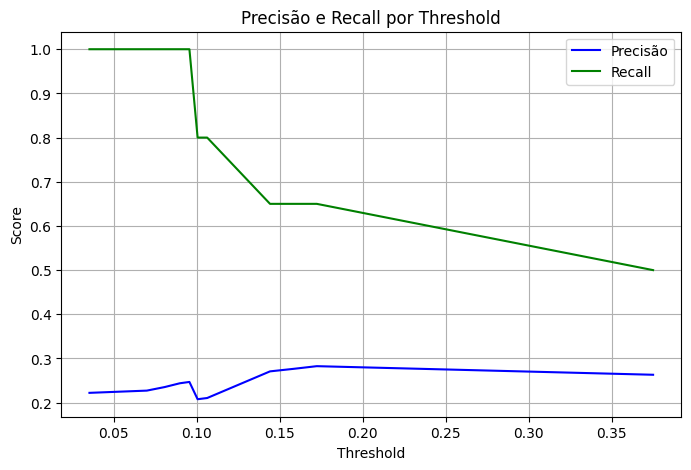

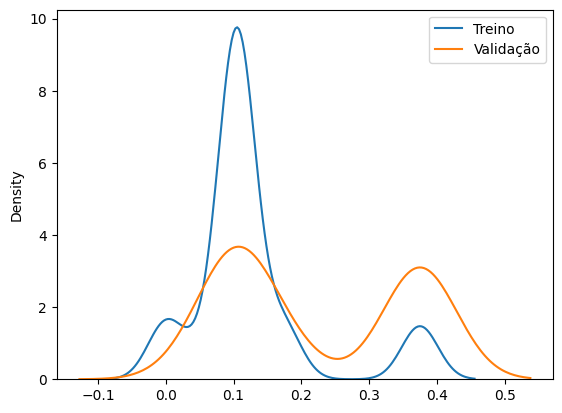

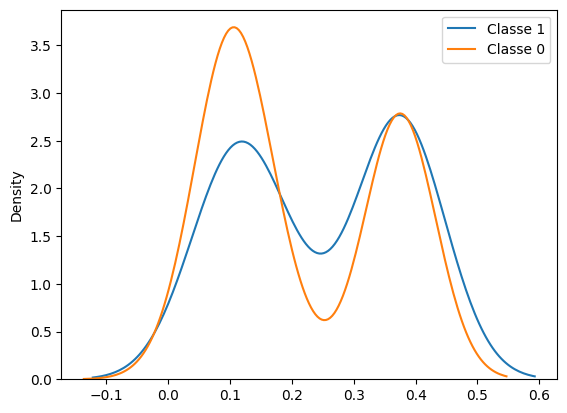

In [22]:
recall_minimo = None
precisao_minima = 0.65
resultado = tr.avaliar_e_logar_modelo(modelo_treinado, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Redução de features

In [23]:
# Importâncias
importancias = pd.Series(modelo_original.feature_importances_, index=X_train.columns)
importancias = importancias.sort_values(ascending=False)
importancias.head(15)


dolar_std                                383.988082
close_max                                321.636002
rsi_std                                  197.508299
close_min                                 87.080560
close_vs_adc_close_mean_geral             72.654927
volume_mean                               69.969299
atr_ultimo                                66.036100
tr_pct_std                                46.350440
macd_hist_std_norm_atr_principal          44.912601
tr_pct_mean                               40.325199
retorno_desde_mudanca_ibov                30.207649
adc_ret_acum_mean_geral_janela            26.155180
adc_macd_hist_ultimo_BBAS3                25.079730
macd_signal_ultimo_norm_atr_principal     19.331218
alpha_papel_vs_ibov_mean                  15.588300
dtype: float64

In [24]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo, _ = criar_e_treinar_modelo_final_com_es_e_calib(
                X_train[colunas_selecionadas], y_train,
                fracao_eval_es=0.25, # Ex: 20% do super treino para ES e calibração prefit
                estrategia_calibracao_cv='prefit'
            )            

            y_pred = modelo.predict(X_val_teste)

            prec = precision_score(y_val_teste, y_pred, zero_division=0)
            rec = recall_score(y_val_teste, y_pred, zero_division=0)

            precisões.append(prec)
            recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 363 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 121 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 47, number of negative: 316
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000095 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 451
[LightGBM] [Info] Number of data points in the train set: 363, number of used features: 5
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[L

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

Treinamento LGBM concluído. Melhor iteração: 73

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (121 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.
Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 363 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 121 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 47, number of negative: 316
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000065 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 451
[LightGBM] [Info] Number of data points in the train set: 363, number of used features: 5
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
T

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

... (270 outputs left out)

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Early stopping, best iteration is:
[4]	valid_0's auc: 0.773473	valid_0's binary_logloss: 0.680375
Tr

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 363 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 121 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 47, number of negative: 316
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000384 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 5518
[LightGBM] [Info] Number of data points in the train set: 363, number of used features: 50
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

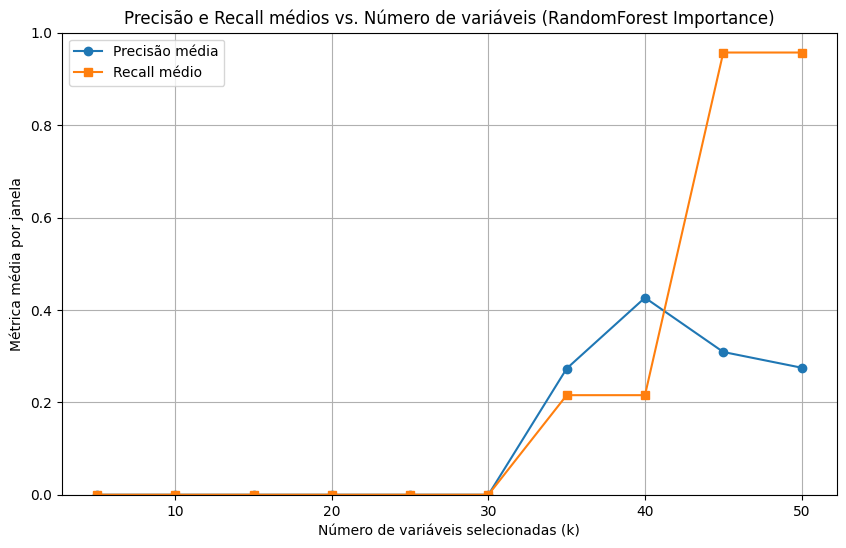

In [25]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (RandomForest Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [26]:
n_features = 20
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['dolar_std',
 'close_max',
 'rsi_std',
 'close_min',
 'close_vs_adc_close_mean_geral',
 'volume_mean',
 'atr_ultimo',
 'tr_pct_std',
 'macd_hist_std_norm_atr_principal',
 'tr_pct_mean',
 'retorno_desde_mudanca_ibov',
 'adc_ret_acum_mean_geral_janela',
 'adc_macd_hist_ultimo_BBAS3',
 'macd_signal_ultimo_norm_atr_principal',
 'alpha_papel_vs_ibov_mean',
 'mm5_vs_mm20',
 'adc_close_trend_ITUB4',
 'retorno_desde_mudanca_dolar',
 'close_std',
 'adc_ret_acum_BBAS3']

In [20]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [32]:
modelo_reduzido, _ = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train_reduzido, y_train,
    fracao_eval_es=0.3, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit',
    metodo_calibracao='isotonic'
)

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 339 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 145 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 71, number of negative: 268
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000153 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2128
[LightGBM] [Info] Number of data points in the train set: 339, number of used features: 20
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.917
AUC na validação: 0.601
Diferença AUC (Treino - Validação): 0.316
PROVÁVEL OVERFITTING
PR AUC no treino: 0.786
PR AUC na validação: 0.499
Diferença PR AUC (Treino - Validação): 0.287
F1 Score no treino: 0.558
F1 Score na validação: 0.190


(np.float64(0.9174545656918629),
 np.float64(0.601438704798253),
 np.float64(0.3160158608936099),
 np.float64(0.785776447037615),
 np.float64(0.49905028110364635),
 np.float64(0.5575254538215687),
 np.float64(0.18970712781553772))

Avaliar e logar modelo
MLflow Run ID: fdf7c9cf9c2e4605b4cea4e5a8f5a402 para ITUB4.SA_20dias_x_0.03val_5dias_alvo
AUC no treino: 0.930
AUC na validação: 0.530

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.917
  Precisão média (em 308 janelas com previsão positiva): 0.915
  Recall médio: 0.450

Calibrando thresholds para precisão mínima de 0.75...

Threshold Ideal Selecionado: 0.50
  Precisão Média Esperada: 91.50%
  Recall Médio Esperado: 45.03%
  Janelas Usadas para Precisão: 308.0

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.615
Recall médio: 0.114
Sinais de compra presentes na vallidação: 25.0
Sinais de compra previstos na validação: 14
Modelo ITUB4.SA_20dias_x_0.03val_5dias_alvo salvo na run fdf7c9cf9c2e4605b4cea4e5a8f5a402


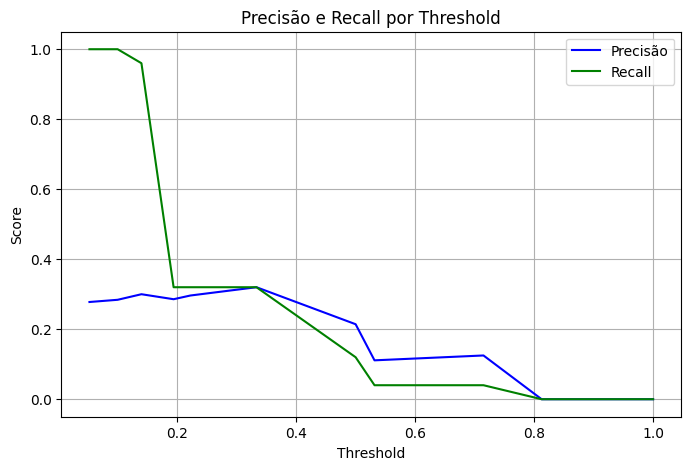

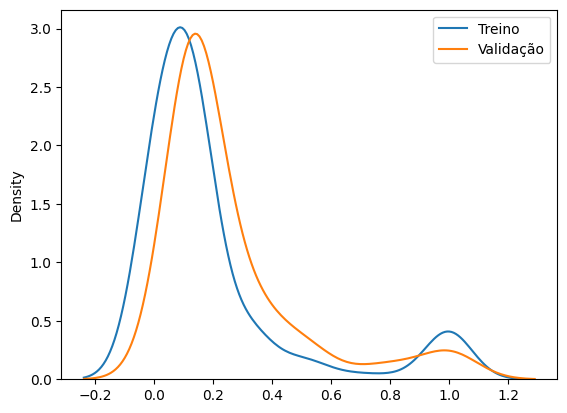

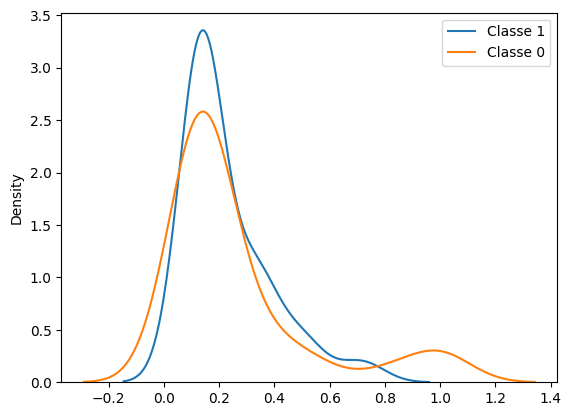

In [33]:
precisao_minima = 0.75
recall_minimo = None
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

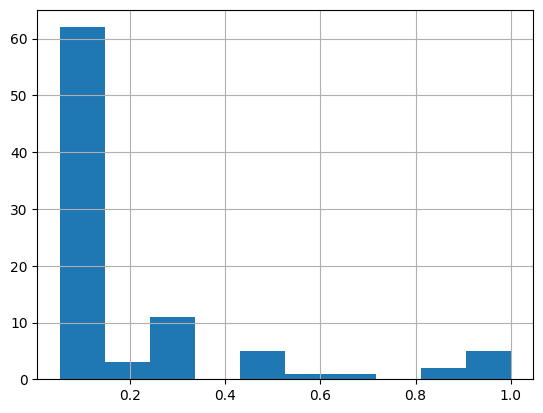

In [34]:
pd.Series(probas).hist()

In [35]:
pd.Series(probas).describe()

count    90.000000
mean      0.254036
std       0.237498
min       0.052632
25%       0.140000
50%       0.140000
75%       0.333333
max       1.000000
dtype: float64